# Adversarial Autoencoder (AAE)

Adversarially match the aggregate encoded distribution to a standard normal prior. There is no per-example KL penalty; reconstruction and adversarial distribution matching are trained in alternating steps.

This standalone notebook includes its own MNIST setup, model components, objective, and training step. Run the cells from top to bottom. The training cell runs 50 epochs on the full MNIST training split. A GPU runtime is recommended in Colab.

## Shared MNIST data and VAE components

The baseline is a small MLP VAE with a diagonal Gaussian posterior and Bernoulli image decoder. We reuse it where the variant changes the objective rather than the architecture.

In [1]:
import math
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

class MLPVAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__(); self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.mu = nn.Linear(400, latent_dim); self.logvar = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 400), nn.ReLU(), nn.Linear(400, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x.flatten(1)); return self.mu(h), self.logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x); z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_terms(recon, x, mu, logvar):
    rec = F.binary_cross_entropy(recon, x, reduction='none').flatten(1).sum(1).mean()
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1).mean()
    return rec, kl

def sample_batch(loader):
    return next(iter(loader))[0].to(device)

## Implementation

The following cell defines this variant's model-specific objective and optimization step.

## 1. Adversarial Autoencoder (AAE)

An AAE matches the aggregate encoded distribution `q(z)` to a chosen prior with a discriminator. It does not impose a per-example Gaussian KL term. The autoencoder preserves information through reconstruction; the encoder tries to fool the discriminator into classifying encoded samples as prior samples. Adversarial matching can be unstable, so balance the discriminator and encoder updates.

In [2]:
class LatentDiscriminator(nn.Module):
    def __init__(self, dim=16):
        super().__init__(); self.net = nn.Sequential(nn.Linear(dim, 128), nn.LeakyReLU(.2), nn.Linear(128, 128), nn.LeakyReLU(.2), nn.Linear(128, 1))
    def forward(self, z): return self.net(z)

aae = MLPVAE().to(device); aae_disc = LatentDiscriminator(aae.latent_dim).to(device)
aae_optim = torch.optim.Adam(aae.parameters(), lr=1e-3)
disc_optim = torch.optim.Adam(aae_disc.parameters(), lr=1e-3)

def aae_train_step(x):
    # Reconstruction update
    aae.train(); aae_disc.train(); x = x.to(device)
    recon, mu, logvar = aae(x); rec, _ = vae_terms(recon, x, mu, logvar)
    aae_optim.zero_grad(); rec.backward(); aae_optim.step()
    # Discriminator: prior is real (1), aggregate encoded samples are fake (0).
    z_enc = aae.reparameterize(*aae.encode(x)).detach()
    z_prior = torch.randn_like(z_enc)
    d_loss = F.binary_cross_entropy_with_logits(aae_disc(z_prior), torch.ones_like(aae_disc(z_prior)))
    d_loss += F.binary_cross_entropy_with_logits(aae_disc(z_enc), torch.zeros_like(aae_disc(z_enc)))
    disc_optim.zero_grad(); d_loss.backward(); disc_optim.step()
    # Encoder adversarial update: encoded samples should look like prior samples.
    z_enc = aae.reparameterize(*aae.encode(x))
    fool_loss = F.binary_cross_entropy_with_logits(aae_disc(z_enc), torch.ones((len(x), 1), device=device))
    aae_optim.zero_grad(); fool_loss.backward(); aae_optim.step()
    return {'reconstruction': rec.item(), 'discriminator': d_loss.item(), 'adversarial': fool_loss.item()}

# Example: metrics = aae_train_step(sample_batch(train_loader))

## Full training — 50 epochs

This runs on the full MNIST training split using the model-specific objective above. In Colab, select a GPU runtime for faster training. The final checkpoint includes model weights, optimizer state, and epoch metrics.

In [3]:
from pathlib import Path

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    totals = {}
    for images, _ in train_loader:
        batch_metrics = aae_train_step(images)
        for name, value in batch_metrics.items():
            totals[name] = totals.get(name, 0.0) + float(value) * images.size(0)
    epoch_metrics = {name: value / len(train_loader.dataset) for name, value in totals.items()}
    history.append(epoch_metrics)
    summary = " | ".join(f"{name}={value:.4f}" for name, value in epoch_metrics.items())
    print(f"Epoch {epoch:02d}/{epochs} | {summary}")

checkpoint = {
    "model": aae.state_dict(),
    "extra_models": {"aae_disc": aae_disc.state_dict()},
    "optimizers": {"aae_optim": aae_optim.state_dict(),
    "disc_optim": disc_optim.state_dict()},
    "epochs": epochs,
    "history": history
}
checkpoint_path = Path("09_AAE_50_epochs.pt")
torch.save(checkpoint, checkpoint_path)
print(f"Saved checkpoint to {checkpoint_path.resolve()}")


Epoch 01/50 | reconstruction=133.2572 | discriminator=0.5831 | adversarial=3.9889
Epoch 05/50 | reconstruction=77.7650 | discriminator=0.7045 | adversarial=1.9462
Epoch 10/50 | reconstruction=73.9060 | discriminator=0.5739 | adversarial=2.5023
Epoch 15/50 | reconstruction=72.3743 | discriminator=0.5303 | adversarial=2.6988
Epoch 20/50 | reconstruction=71.4614 | discriminator=0.5196 | adversarial=2.8227
Epoch 25/50 | reconstruction=70.7811 | discriminator=0.5147 | adversarial=2.8478
Epoch 30/50 | reconstruction=70.2967 | discriminator=0.5073 | adversarial=2.9038
Epoch 35/50 | reconstruction=69.9247 | discriminator=0.5016 | adversarial=2.9657
Epoch 40/50 | reconstruction=69.5936 | discriminator=0.4957 | adversarial=2.9996
Epoch 45/50 | reconstruction=69.3341 | discriminator=0.4880 | adversarial=3.0331
Epoch 50/50 | reconstruction=69.1300 | discriminator=0.4876 | adversarial=3.0712
Saved checkpoint to /content/09_AAE_50_epochs.pt


## Inspect reconstructions, prior samples, and aggregate matching

Use these plots alongside the objective metrics; no single number captures reconstruction quality, prior matching, latent use, and sample quality.

Discriminator mean probability of prior as real: 0.882
Discriminator mean probability of encoded samples as real: 0.113


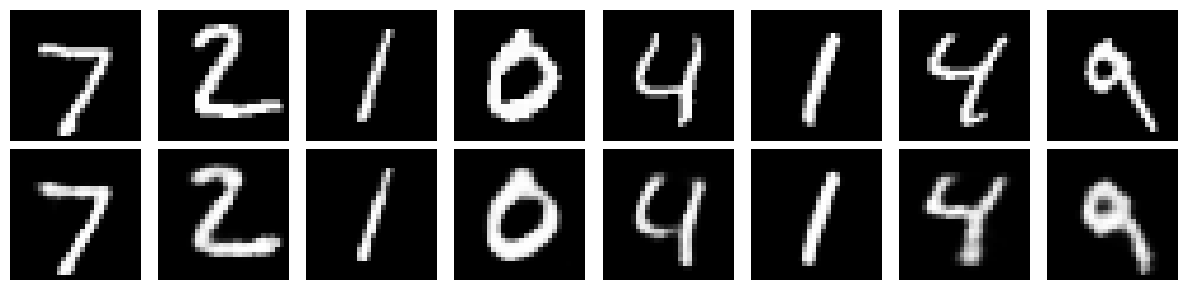

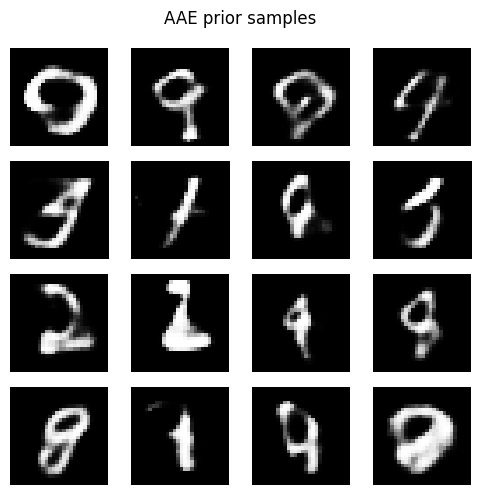

In [4]:
x = sample_batch(test_loader)[:8]
aae.eval()
with torch.no_grad():
    recon, _, _ = aae(x)
    z_prior = torch.randn(16, aae.latent_dim, device=device)
    prior_samples = aae.decode(z_prior)
    z_encoded = aae.reparameterize(*aae.encode(x))
    d_prior = torch.sigmoid(aae_disc(z_prior)).mean().item()
    d_encoded = torch.sigmoid(aae_disc(z_encoded)).mean().item()
print(f'Discriminator mean probability of prior as real: {d_prior:.3f}')
print(f'Discriminator mean probability of encoded samples as real: {d_encoded:.3f}')
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(x[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, prior_samples):
    ax.imshow(image[0].cpu(), cmap='gray'); ax.axis('off')
plt.suptitle('AAE prior samples'); plt.tight_layout(); plt.show()